# 🏷️ AI Task Type & Contribution Type — F1–F6

Notebook phân tích hai nhãn do LLM gán cho từng comment AI trong `data/processed/commit_annotations_llm.csv`:

- **`AI_task_type`** — AI được dùng cho *việc gì* (viết code, tài liệu, test, sửa bug…).
- **`AI_contribution_type`** — AI đóng góp *theo cách nào* (sinh code, sinh artifact, hỗ trợ kiến thức…).

Dữ liệu được nối với `commits_features.csv` qua `id` để lấy `ai_tool`, `year`, `is_modified`. Hình lưu vào `reports/figures/` (tiền tố `F`), bảng kiểm định lưu vào `reports/`.

**Lưu ý:** nhãn `False Positive` nghĩa là comment không thực sự nói về code do AI tạo. Các phân tích theo AI tool và năm (F3, F4) loại các dòng mà *một trong hai* nhãn là `False Positive`. Cramér's V: < 0,1 không đáng kể, 0,1–0,3 nhỏ, 0,3–0,5 trung bình, > 0,5 lớn.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from sklearn.metrics import cohen_kappa_score
from IPython.display import display
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

ANN_PATH = Path('../data/processed/commit_annotations_llm.csv')
FEAT_PATH = Path('../data/processed/commits_features.csv')
FIG_DIR = Path('../reports/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = Path('../reports')
TASK, CONTRIB, FP = 'AI_task_type', 'AI_contribution_type', 'False Positive'
ALPHA = 0.05

ann = pd.read_csv(ANN_PATH)
n_raw = len(ann); ann = ann.drop_duplicates('id')
# Nhãn do LLM sinh ra: dừng ngay nếu có nhãn nằm ngoài taxonomy
TASK_LABELS = {'Code Implementation', 'Code Enhancement', 'Documentation', 'Testing', 'Bug Identification & Fixing', 'Generic Mention and Indeterminate Actions', FP}
CONTRIB_LABELS = {'Implementation', 'Artifact Generation', 'Knowledge and Concept Support', 'Generic Mention and Indeterminate Actions', FP}
assert set(ann[TASK]) <= TASK_LABELS and set(ann[CONTRIB]) <= CONTRIB_LABELS, 'Có nhãn ngoài taxonomy'
ann[[TASK, CONTRIB]] = ann[[TASK, CONTRIB]].replace({'Generic Mention and Indeterminate Actions': 'Generic / Indeterminate', 'Bug Identification & Fixing': 'Bug Fixing', 'Knowledge and Concept Support': 'Knowledge Support'})

feat = pd.read_csv(FEAT_PATH, low_memory=False, usecols=['id', 'year', 'is_modified', 'ai_tool'])
df = ann.merge(feat, on='id', how='left', validate='one_to_one')
valid = df[(df[TASK] != FP) & (df[CONTRIB] != FP)]
print(f'✅ Đã tải {n_raw:,} dòng, bỏ {n_raw - len(ann)} dòng trùng id → {len(df):,} dòng; khớp commits_features: {df["year"].notna().mean():.1%}')
print(f'Dòng không False Positive ở cả hai nhãn: {len(valid):,} ({len(valid) / len(df):.1%})')

# Thứ tự và màu cố định theo tần suất, dùng chung cho mọi biểu đồ
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ORDER = {c: df[c].value_counts().index.tolist() for c in [TASK, CONTRIB]}
COLORS = {c: dict(zip(ORDER[c], PALETTE)) for c in [TASK, CONTRIB]}

def savefig(name):
    path = FIG_DIR / name
    plt.tight_layout(); plt.savefig(path, dpi=160, bbox_inches='tight'); print(f'Đã lưu {path}')
    plt.show(); plt.close()

def ink(color):
    # chữ tối trên nền sáng, chữ trắng trên nền tối
    r, g, b = to_rgb(color); return '#1a1a19' if 0.2126*r + 0.7152*g + 0.0722*b > 0.45 else 'white'

def stacked_share(ct, col, ax, title):
    share = ct[[c for c in ORDER[col] if c in ct]].pipe(lambda t: t.div(t.sum(axis=1), axis=0))
    share.plot(kind='barh', stacked=True, ax=ax, width=0.8, color=[COLORS[col][c] for c in share], edgecolor='white', linewidth=1.5)
    for bars, c in zip(ax.containers, share):
        ax.bar_label(bars, labels=[f'{w:.0%}' if w >= .06 else '' for w in share[c]], label_type='center', fontsize=8, color=ink(COLORS[col][c]))
    ax.set_yticklabels([f'{i} (n={n:,})' for i, n in ct.sum(axis=1).items()])
    ax.set(title=title, xlabel='', ylabel='', xlim=(0, 1)); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)

tests = []
def chi_square(name, table):
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum(); v = np.sqrt(chi2 / n / max(1, min(table.shape) - 1))
    tests.append({'question': name, 'chi2': chi2, 'dof': dof, 'p_value': p, 'cramers_v': v, 'n': n, 'significant_α_0.05': p < ALPHA})
    print(f'{name}: χ²={chi2:,.1f}, dof={dof}, p={p:.2e}, Cramér V={v:.3f}')

def wilson_ci(success, n, confidence=.95):
    z = stats.norm.ppf(1 - (1-confidence)/2); phat = success/n; den = 1 + z*z/n
    center = (phat + z*z/(2*n))/den; half = z*np.sqrt(phat*(1-phat)/n + z*z/(4*n*n))/den
    return center-half, center+half

✅ Đã tải 24,225 dòng, bỏ 1 dòng trùng id → 24,224 dòng; khớp commits_features: 100.0%
Dòng không False Positive ở cả hai nhãn: 20,268 (83.7%)


## F1 — Phân phối nhãn

Đã lưu ../reports/figures/F1_01_label_distribution.png


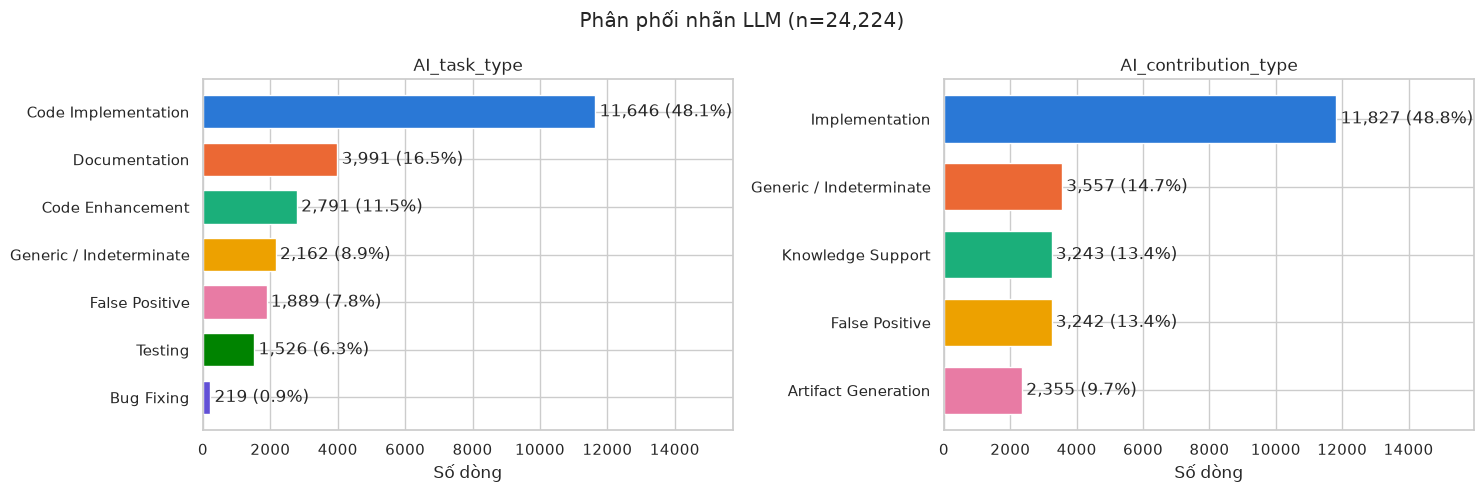

count  share
AI_task_type         Code Implementation      11646  0.481
                     Documentation             3991  0.165
                     Code Enhancement          2791  0.115
                     Generic / Indeterminate   2162  0.089
                     False Positive            1889  0.078
                     Testing                   1526  0.063
                     Bug Fixing                 219  0.009
AI_contribution_type Implementation           11827  0.488
                     Generic / Indeterminate   3557  0.147
                     Knowledge Support         3243  0.134
                     False Positive            3242  0.134
                     Artifact Generation       2355  0.097

AI_task_type × language: χ²=468.6, dof=6, p=4.81e-98, Cramér V=0.139
AI_contribution_type × language: χ²=163.2, dof=4, p=2.95e-34, Cramér V=0.082


Đã lưu ../reports/figures/F1_02_labels_by_language.png


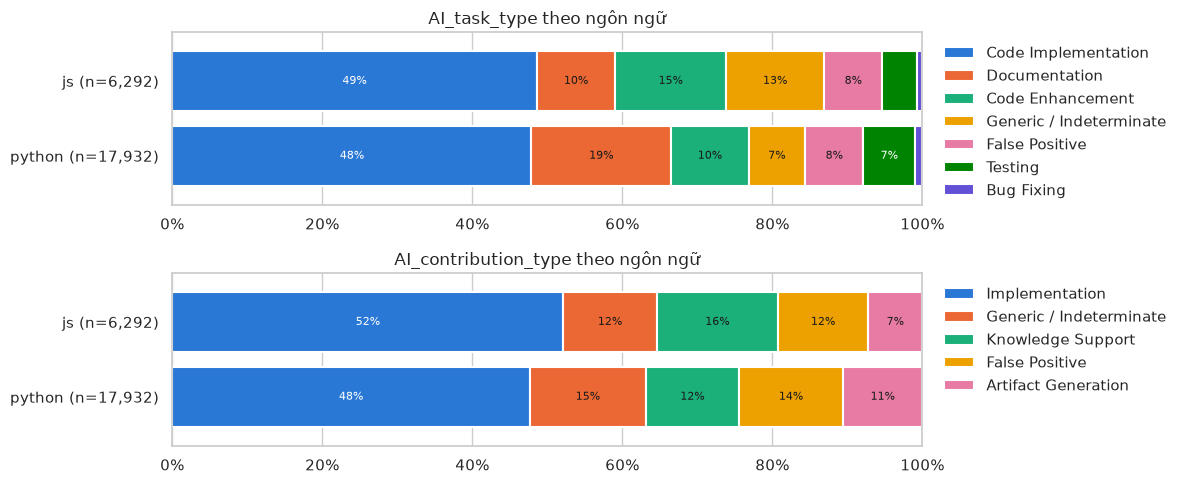

In [2]:
# F1.1 — Số lượng mỗi nhãn
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, [TASK, CONTRIB]):
    counts = df[col].value_counts().reindex(ORDER[col])
    ax.barh(counts.index, counts.values, color=[COLORS[col][c] for c in counts.index], height=0.7)
    ax.bar_label(ax.containers[0], labels=[f'{v:,} ({v / len(df):.1%})' for v in counts], padding=3)
    ax.set(title=col, xlabel='Số dòng', xlim=(0, counts.max() * 1.35)); ax.invert_yaxis()
fig.suptitle(f'Phân phối nhãn LLM (n={len(df):,})'); savefig('F1_01_label_distribution.png')
display(pd.concat({c: df[c].value_counts().to_frame('count').assign(share=lambda t: (t['count'] / len(df)).round(3)) for c in [TASK, CONTRIB]}))

# F1.2 — Theo ngôn ngữ
fig, axes = plt.subplots(2, 1, figsize=(12, 5))
for ax, col in zip(axes, [TASK, CONTRIB]):
    ct = pd.crosstab(df['language'], df[col])
    stacked_share(ct, col, ax, f'{col} theo ngôn ngữ'); chi_square(f'{col} × language', ct)
savefig('F1_02_labels_by_language.png')

## F2 — Quan hệ giữa task type và contribution type

Đã lưu ../reports/figures/F2_01_task_x_contribution.png


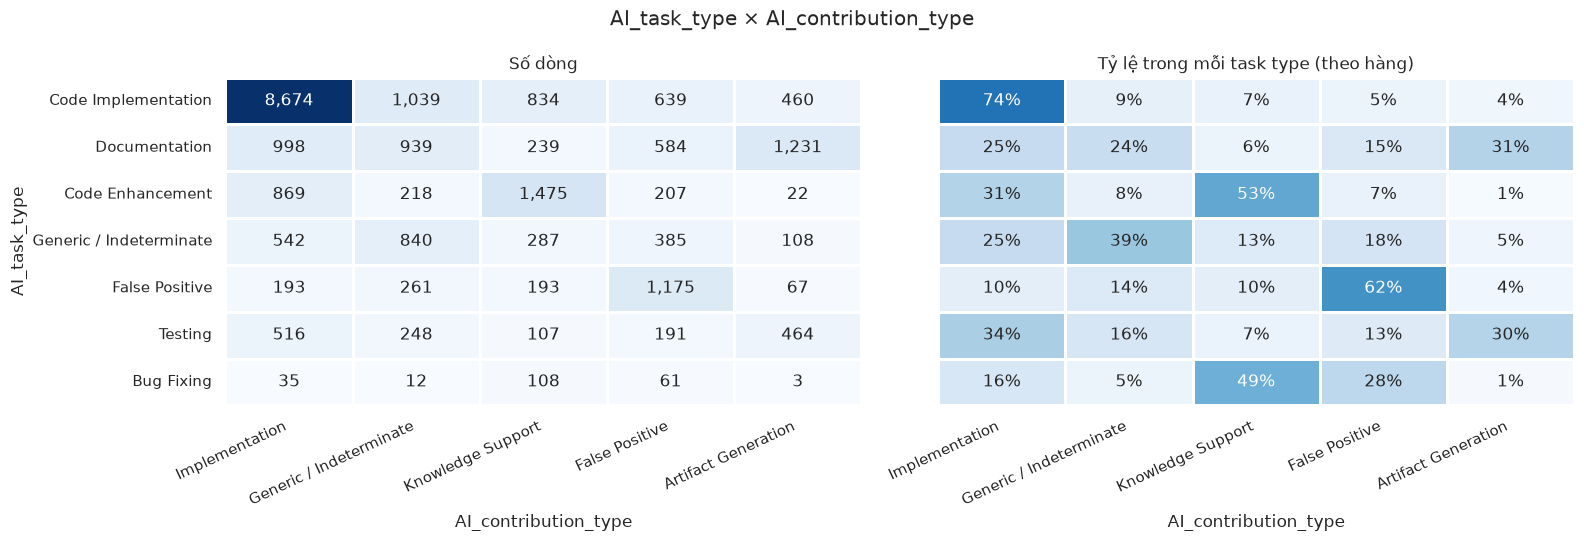

AI_task_type × AI_contribution_type: χ²=15,941.5, dof=24, p=0.00e+00, Cramér V=0.406


contribution = FP,False,True,All
task = FP,,,
False,20268,2067,22335
True,714,1175,1889
All,20982,3242,24224


Cohen's κ giữa hai cờ False Positive: 0.399


In [3]:
# F2.1 — Ma trận task × contribution
task_contrib = pd.crosstab(df[TASK], df[CONTRIB]).loc[ORDER[TASK], ORDER[CONTRIB]]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
sns.heatmap(task_contrib, annot=True, fmt=',d', cmap='Blues', cbar=False, linewidths=1, linecolor='white', ax=axes[0]); axes[0].set_title('Số dòng')
sns.heatmap(task_contrib.div(task_contrib.sum(axis=1), axis=0), annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1, cbar=False, linewidths=1, linecolor='white', ax=axes[1])
axes[1].set(title='Tỷ lệ trong mỗi task type (theo hàng)', ylabel='')
for ax in axes: plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
fig.suptitle('AI_task_type × AI_contribution_type'); savefig('F2_01_task_x_contribution.png')
chi_square(f'{TASK} × {CONTRIB}', task_contrib)

# F2.2 — Hai nhãn có đồng thuận về False Positive không?
fp_task, fp_contrib = df[TASK].eq(FP), df[CONTRIB].eq(FP)
display(pd.crosstab(fp_task.rename('task = FP'), fp_contrib.rename('contribution = FP'), margins=True))
print(f"Cohen's κ giữa hai cờ False Positive: {cohen_kappa_score(fp_task, fp_contrib):.3f}")

## F3 — Theo AI tool

Chỉ dùng các dòng không bị gán `False Positive`. `ai_tool` lấy từ `commits_features.csv` (trích từ comment ở notebook 03).

AI_task_type × ai_tool: χ²=2,103.7, dof=35, p=0.00e+00, Cramér V=0.144
AI_contribution_type × ai_tool: χ²=2,043.1, dof=21, p=0.00e+00, Cramér V=0.183


Đã lưu ../reports/figures/F3_01_labels_by_ai_tool.png


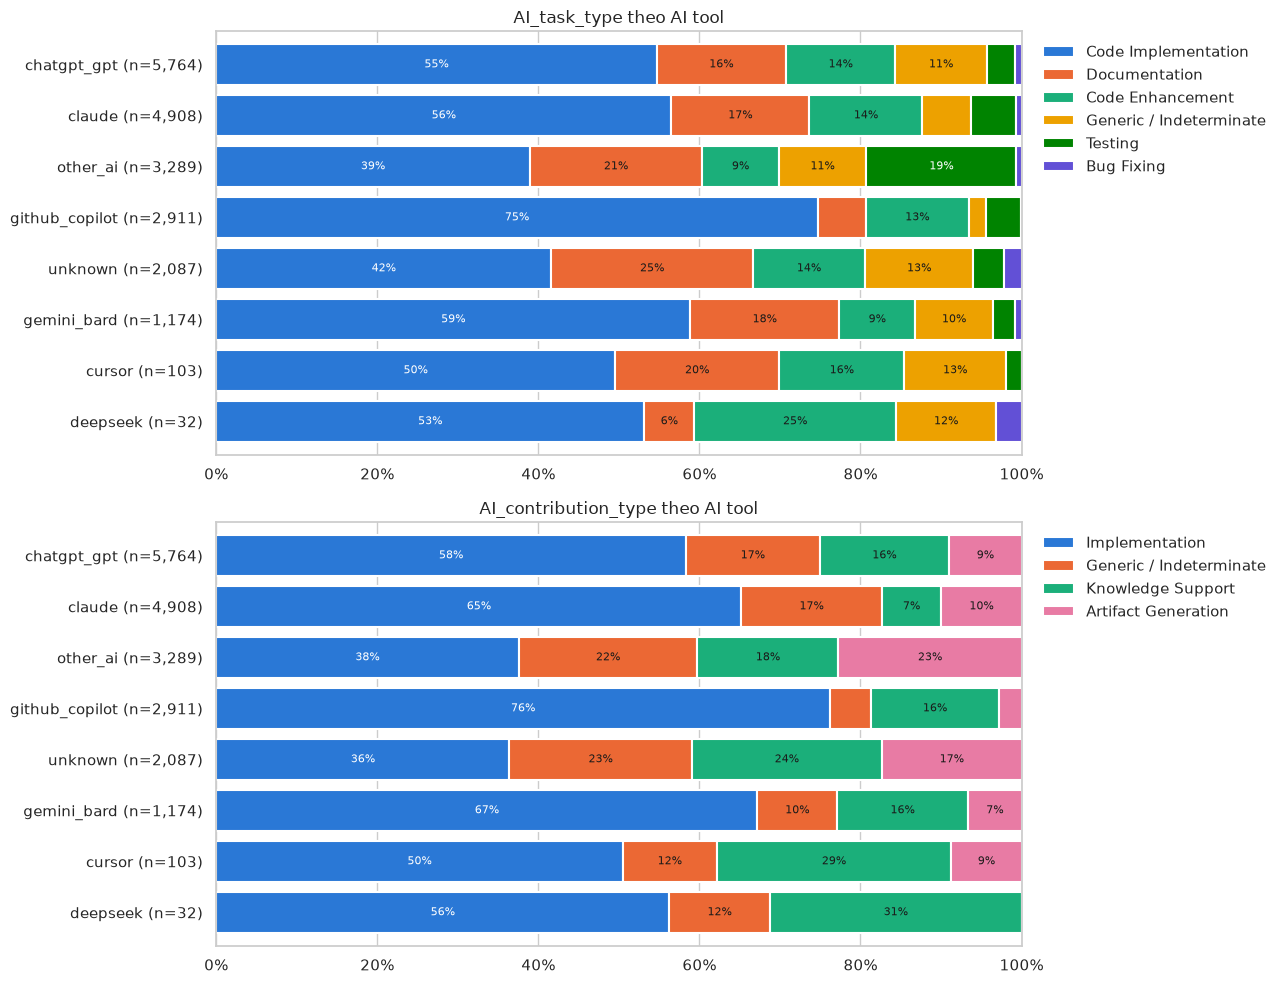

In [4]:
tool_order = valid['ai_tool'].value_counts().index
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, col in zip(axes, [TASK, CONTRIB]):
    ct = pd.crosstab(valid['ai_tool'], valid[col]).loc[tool_order]
    stacked_share(ct, col, ax, f'{col} theo AI tool'); chi_square(f'{col} × ai_tool', ct)
savefig('F3_01_labels_by_ai_tool.png')

## F4 — Xu hướng theo năm

AI_task_type × year: χ²=599.5, dof=20, p=3.73e-114, Cramér V=0.086
AI_contribution_type × year: χ²=276.3, dof=12, p=4.33e-52, Cramér V=0.067


Đã lưu ../reports/figures/F4_01_labels_by_year.png


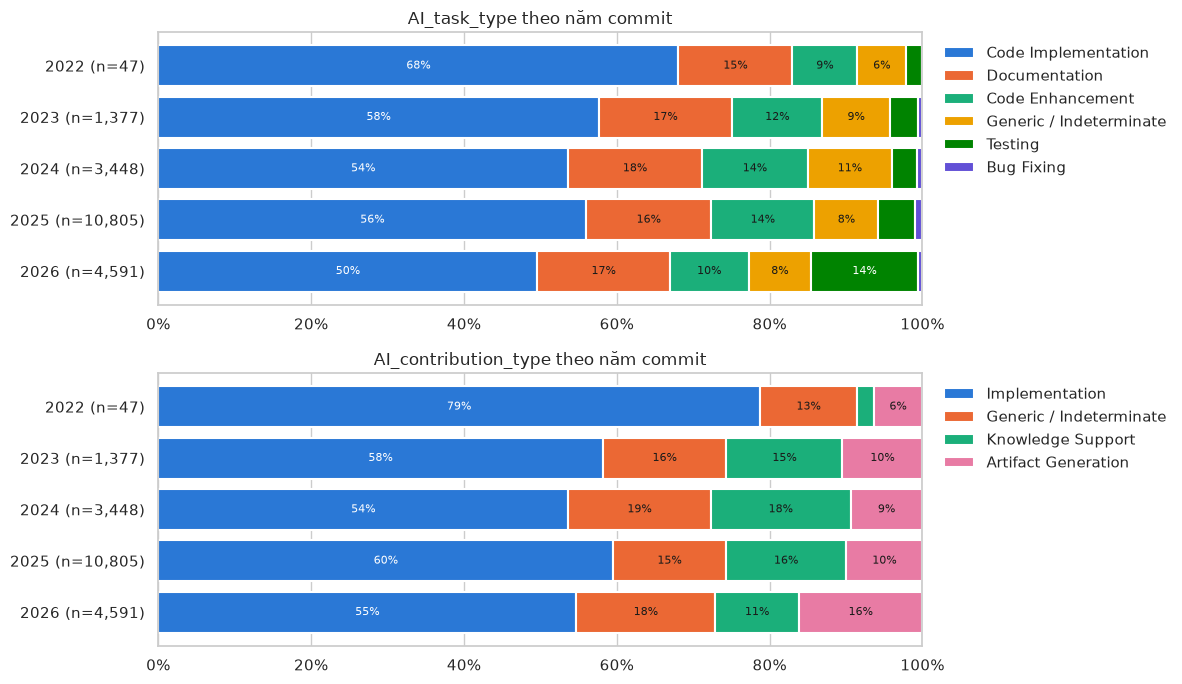

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, col in zip(axes, [TASK, CONTRIB]):
    ct = pd.crosstab(valid['year'], valid[col])
    stacked_share(ct, col, ax, f'{col} theo năm commit'); chi_square(f'{col} × year', ct)
savefig('F4_01_labels_by_year.png')

## F5 — Nhãn có liên quan đến việc code AI bị sửa sau này không?

Outcome là `is_modified` (dòng code AI có bị commit sau sửa lại). Khoảng tin cậy 95% dùng Wilson; đường nét đứt là tỷ lệ chung.

AI_task_type × is_modified: χ²=60.9, dof=6, p=2.97e-11, Cramér V=0.050
AI_contribution_type × is_modified: χ²=25.7, dof=4, p=3.69e-05, Cramér V=0.033


Đã lưu ../reports/figures/F5_01_modification_rate.png


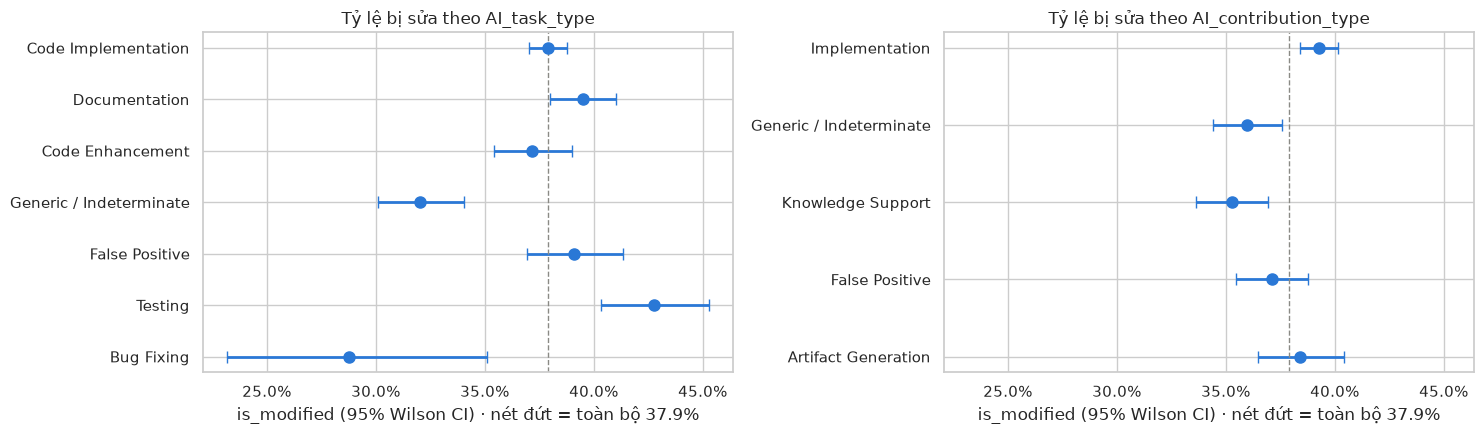

,sum,size,rate,ci_low,ci_high,variable
Code Implementation,4414,11646,0.379,0.370,0.388,AI_task_type
Documentation,1577,3991,0.395,0.380,0.410,AI_task_type
Code Enhancement,1038,2791,0.372,0.354,0.390,AI_task_type
Generic / Indeterminate,693,2162,0.321,0.301,0.341,AI_task_type
False Positive,739,1889,0.391,0.369,0.413,AI_task_type
Testing,653,1526,0.428,0.403,0.453,AI_task_type
Bug Fixing,63,219,0.288,0.232,0.351,AI_task_type
Implementation,4645,11827,0.393,0.384,0.402,AI_contribution_type
Generic / Indeterminate,1280,3557,0.360,0.344,0.376,AI_contribution_type
Knowledge Support,1144,3243,0.353,0.336,0.369,AI_contribution_type


In [6]:
base = df['is_modified'].mean(); rates = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, col in zip(axes, [TASK, CONTRIB]):
    g = df.groupby(col)['is_modified'].agg(['sum', 'size']).loc[ORDER[col]]
    g['rate'] = g['sum'] / g['size']; g['ci_low'], g['ci_high'] = wilson_ci(g['sum'], g['size'])
    ax.errorbar(g['rate'], g.index, xerr=[g['rate'] - g['ci_low'], g['ci_high'] - g['rate']], fmt='o', ms=8, lw=2, capsize=4, color='#2a78d6')
    ax.axvline(base, color='#8a8a85', ls='--', lw=1)
    ax.set(title=f'Tỷ lệ bị sửa theo {col}', xlabel=f'is_modified (95% Wilson CI) · nét đứt = toàn bộ {base:.1%}'); ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.invert_yaxis()
    chi_square(f'{col} × is_modified', pd.crosstab(df[col], df['is_modified']))
    rates.append(g.assign(variable=col))
savefig('F5_01_modification_rate.png')
display(pd.concat(rates).round(3))

## F6 — Ví dụ comment theo task type

Kiểm tra định tính xem nhãn LLM có hợp lý không.

In [7]:
for t in ORDER[TASK]:
    print(f'\n=== {t} ===')
    for c in df.loc[df[TASK] == t, 'comment'].sample(3, random_state=42): print('  •', c[:160])


=== Code Implementation ===
  • tokyonight defines colors specified by tokyonightabc. the color values are generated by github copilot. """
  • lazy initialize llm service to avoid startup delays - claude generated"""
  • 📚 <b>new book release!</b> <b>📖 {title}</b> <i>by {author}</i> 🎭 <b>genre:</b> {genre} 📝 <b>description:</b> {description} ✨ <i>generated with ai-powered creati

=== Documentation ===
  • day 1: stack docstring generated by copilot: =============================== stacks are a very common data structure and it's going to be important that you kno
  • generated by chatgpt
  • ruff: noqa: e501 # a prompt containing a large markdown table. the table is randomly generated by gpt-4.

=== Code Enhancement ===
  • appends text chunks to the results_edit qtextedit with enhanced feedback - claude generated"""
  • knight move patterns: (±1, ±2) and (±2, ±1) ## llm tool copilot suggested this line code below
  • generated by claude //---------------------- // handle invalid inp

## Lưu kết quả

In [8]:
tests_df = pd.DataFrame(tests); display(tests_df)
tests_df.to_csv(REPORT_DIR / 'annotation_chi_square_tests.csv', index=False)
task_contrib.to_csv(REPORT_DIR / 'annotation_task_x_contribution.csv')
print('Đã lưu annotation_chi_square_tests.csv và annotation_task_x_contribution.csv')

,question,chi2,dof,p_value,cramers_v,n,significant_α_0.05
0,AI_task_type × language,468.624369,6,4.805935e-98,0.139088,24224,True
1,AI_contribution_type × language,163.240714,4,2.949962e-34,0.082090,24224,True
2,AI_task_type × AI_contribution_type,15941.515365,24,0.000000e+00,0.405613,24224,True
3,AI_task_type × ai_tool,2103.729604,35,0.000000e+00,0.144080,20268,True
4,AI_contribution_type × ai_tool,2043.089506,21,0.000000e+00,0.183306,20268,True
5,AI_task_type × year,599.463341,20,3.734345e-114,0.085990,20268,True
6,AI_contribution_type × year,276.318777,12,4.332602e-52,0.067412,20268,True
7,AI_task_type × is_modified,60.890126,6,2.967503e-11,0.050136,24224,True
8,AI_contribution_type × is_modified,25.670086,4,3.688010e-05,0.032553,24224,True


Đã lưu annotation_chi_square_tests.csv và annotation_task_x_contribution.csv


## Nhận xét

*(Số liệu từ lần chạy trên 24.224 dòng annotation; chạy lại notebook nếu dữ liệu thay đổi.)*

- **Phân phối:** AI chủ yếu được dùng để viết code — `Code Implementation` chiếm 48% task type và `Implementation` chiếm 49% contribution type. `Documentation` (16,5%) là task lớn thứ hai; `Bug Fixing` rất hiếm (0,9%).
- **Task × contribution liên hệ mạnh** (Cramér's V = 0,41): `Code Enhancement` và `Bug Fixing` chủ yếu là `Knowledge Support` (53% và 49%), còn `Documentation` và `Testing` hay đi với `Artifact Generation` (~30%). Hai nhãn bổ sung cho nhau chứ không trùng lặp.
- **False Positive không nhất quán giữa hai nhãn:** Cohen's κ = 0,40 (trung bình). Có 2.067 dòng chỉ bị gán FP ở contribution và 714 dòng chỉ ở task → nên kiểm tra thủ công một mẫu trước khi dùng nhãn FP để lọc dữ liệu.
- **Theo AI tool** (V ≈ 0,14–0,18, nhỏ): GitHub Copilot thiên về viết code (75% `Code Implementation`); nhóm `other_ai` có tỷ lệ `Testing` (19%) và `Artifact Generation` (23%) cao nhất.
- **Theo năm và ngôn ngữ:** khác biệt có ý nghĩa thống kê nhưng effect size nhỏ (V < 0,14). Năm 2026 tỷ lệ `Testing` tăng lên 14% và `Artifact Generation` lên 16%.
- **Liên hệ với `is_modified`:** gần như không đáng kể (V ≤ 0,05). Code gán `Testing` bị sửa nhiều nhất (42,8%), `Generic / Indeterminate` (32,1%) và `Bug Fixing` (28,8%, CI rộng vì n = 219) bị sửa ít nhất.
- Với n lớn, mọi kiểm định chi-square đều có p < 0,05; nên đọc **effect size** thay vì p-value. Các dòng cùng một commit/repo không độc lập nên p-value có thể bị đánh giá thấp.